# Chapter 21: Experimental Markets, Learning, and Preference Elicitation

This notebook reruns four worked examples from the chapter: a valuation gap that shrinks with market experience, level-k reasoning in a guess-two-thirds-of-the-average game, a double auction against a one-shot sealed round, and a preference reversal between choice and pricing. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def plural(count, singular, plural_form=None):
    """'1 trip', '3 trips', '0 trips'. Count is printed as an integer when whole."""
    word = singular if count == 1 else (plural_form or singular + "s")
    shown = str(int(count)) if float(count).is_integer() else str(count)
    return f"{shown} {word}"


def join_and(items):
    """'a', 'a and b', 'a, b and c'."""
    items = [str(i) for i in items]
    if len(items) <= 1:
        return "".join(items)
    return ", ".join(items[:-1]) + " and " + items[-1]


def expected_value(outcomes, probs):
    """Probability-weighted mean of outcomes. expected-utility-theorem: E[X] = 0.5(100) + 0.5(25) = 62.5."""
    if abs(sum(probs) - 1.0) > 1e-9:
        raise ValueError("probabilities must sum to one")
    return float(sum(p * x for p, x in zip(probs, outcomes)))


def wta_wtp_gap(ask, bid):
    """market-experience-effect: valuation gap A = ask - bid.

    Book (ch021): novices A(0) = 16 - 8 = 8; after ten rounds A(10) = 12 - 10 = 2.
    """
    return float(ask) - float(bid)


def level_k_choices(p, start=50.0, k=3):
    """beauty-contest-convergence: level-k choices start p^j for j = 0..k.

    Book (ch021): p = 2/3 from 50 gives 50, 33.33, 22.22, 14.81.
    """
    return [start * p ** j for j in range(k + 1)]


def beauty_round(choices, p):
    """beauty-contest-convergence: mean, target p * mean and the winning (closest) choices.

    Book (ch021): 50, 40, 35, 30, 25, 18 gives mean 33, target 22, winner 25;
    20, 18, 17, 16, 15, 13 gives mean 16.5, target 11.
    """
    mean = sum(choices) / len(choices)
    target = p * mean
    best = min(abs(c - target) for c in choices)
    winners = [c for c in choices if abs(abs(c - target) - best) < 1e-9]
    return {"mean": mean, "target": target, "winners": winners}


def efficient_trades(values, costs):
    """double-auction-convergence: pair highest values with lowest costs; Q* and maximum surplus.

    Book (ch021): values 100, 90, 80, 70 and costs 30, 50, 75, 95 give gains 70, 40, 5, -25,
    Q* = 3, surplus 115, price band 75 to 80.
    """
    v = sorted(values, reverse=True)
    c = sorted(costs)
    gains = [a - b for a, b in zip(v, c)]
    q = sum(1 for g in gains if g > 0)
    surplus = sum(g for g in gains if g > 0)
    lo = max(c[q - 1], v[q] if q < len(v) else c[q - 1]) if q else None
    hi = min(v[q - 1], c[q] if q < len(c) else v[q - 1]) if q else None
    return {"gains": gains, "q": q, "surplus": surplus, "band": (lo, hi)}


def sealed_round(bids, asks, values, costs):
    """double-auction-convergence: one-shot sealed round, highest bid meets lowest ask while bid >= ask.

    Trading pairs are matched in rank order; surplus uses the matched units' true values and costs
    (bids and asks listed in the same order as values and costs). Book (ch021): only 65 crosses 40,
    one trade, surplus 100 - 30 = 70.
    """
    b = sorted(zip(bids, values), reverse=True)
    a = sorted(zip(asks, costs))
    trades = [(bb, aa) for bb, aa in zip(b, a) if bb[0] >= aa[0]]
    surplus = sum(bb[1] - aa[1] for bb, aa in trades)
    return {"q": len(trades), "surplus": surplus, "pairs": [(bb[0], aa[0]) for bb, aa in trades]}


plt.rcParams.update(HOUSE_RC)


choice = SimpleNamespace(expected_value=expected_value)


behavioral = SimpleNamespace(wta_wtp_gap=wta_wtp_gap, level_k_choices=level_k_choices, beauty_round=beauty_round, efficient_trades=efficient_trades, sealed_round=sealed_round)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'market-experience-effect': {'value': 10,
                              'ask_0': 16,
                              'bid_0': 8,
                              'gap_0': 8,
                              'ask_10': 12,
                              'bid_10': 10,
                              'gap_10': 2,
                              'posted_price': 12,
                              'midpoint': 11,
                              'fall': 6},
 'beauty-contest-convergence': {'p': 0.6666666666666666,
                                'start': 50,
                                'levels': [50, 33.33, 22.22, 14.81],
                                'round_1': [50, 40, 35, 30, 25, 18],
                                'mean_1': 33,
                                'target_1': 22,
                                'winner_1': 25,
                                'round_2': [20, 18, 17, 16, 15, 13],
                                'sum_2': 99,
                                'mean_2': 16.5,
                                'target_2': 11,
                                'p_counterfactual': 1,
                                'all_choose': 40},
 'double-auction-convergence': {'values': [100, 90, 80, 70],
                                'costs': [30, 50, 75, 95],
                                'gains': [70, 40, 5, -25],
                                'q_star': 3,
                                'max_surplus': 115,
                                'band': [75, 80],
                                'sealed_bids': [65, 55, 45, 35],
                                'sealed_asks': [40, 60, 76, 96],
                                'sealed_q': 1,
                                'sealed_surplus': 70},
 'preference-reversal': {'p_prob': 0.8,
                         'p_prize': 30,
                         'd_prob': 0.25,
                         'd_prize': 100,
                         'ev_P': 24,
                         'ev_D': 25,
                         'ce_P': 20,
                         'ce_D': 28,
                         'choice': 'P'},
 'constructed': {'market-experience-effect': {'posted_price': [9]},
                 'beauty-contest-convergence': {'p': [0.5]},
                 'double-auction-convergence': {'c3': [60, 85]},
                 'preference-reversal': {'d_prob': [0.2, 0.3], 'ce_D': [18]}}}


P_VALUES = {"1/2": 0.5, "2/3": 2 / 3, "1": 1.0}


def gap_picture(r=1, p=12):
    b = BV["market-experience-effect"]
    ask, bid = (b["ask_0"], b["bid_0"]) if r == 1 else (b["ask_10"], b["bid_10"])
    gap = behavioral.wta_wtp_gap(ask, bid)
    sell = p >= ask
    buy = p <= bid
    fig, ax = new_figure()
    ax.axvspan(bid, ask, color=PALETTE["gold"], alpha=0.25)
    ax.plot([6, 18], [0, 0], color=PALETTE["grey"], linewidth=1.2)
    mark(ax, bid, 0, f"buyers offer {money(bid, 0)}", col="teal", dx=0, dy=14, ha="center")
    mark(ax, ask, 0, f"owners ask {money(ask, 0)}", col="navy", dx=0, dy=-16, ha="center", va="top")
    ax.axvline(p, ymin=0.5, color=PALETTE["terracotta"], linestyle="dashed", linewidth=1.6)
    label(ax, p, 0.75, f"posted price {money(p, 0)}", col="terracotta", dx=6, dy=0)
    label(ax, bid + 0.2, -0.6, f"gap A = {money(gap, 0)}", col="ink", dx=0, dy=0, ha="left")
    ax.set_xlim(6, 18)
    ax.set_ylim(-1, 1)
    ax.set_yticks([])
    ax.set_xlabel("Dollars per card")
    ax.set_ylabel("Round " + str(r))
    who = "Novices (round 1)" if r == 1 else "Experienced traders (round 11)"
    if sell and buy:
        verdict = (f"At {money(p, 0)} owners accept (price at or above the {money(ask, 0)} ask) and buyers accept "
                   f"(price at or below the {money(bid, 0)} offer), so trade is possible.")
    else:
        reasons = []
        if not sell:
            reasons.append(f"owners want at least {money(ask, 0)}")
        if not buy:
            reasons.append(f"buyers pay at most {money(bid, 0)}")
        verdict = f"At {money(p, 0)} no trade happens: {join_and(reasons)}."
    if bid < ask:
        verdict += (f" With these typical quotes no single price satisfies both sides; trades near the "
                    f"{money((bid + ask) / 2, 0)} midpoint need traders whose own quotes are closer than average.")
    metrics = {"Owners' ask": money(ask, 0), "Buyers' offer": money(bid, 0), "Valuation gap A": money(gap, 0),
               "Trade at posted price (typical quotes)": "Yes" if (sell and buy) else "No"}
    interp = (f"{who}: A = {num(ask, 0)} - {num(bid, 0)} = {num(gap, 0)} dollars. {verdict} Experience shrinks the "
              f"gap from $8 to $2, a fall of $6, but the average alone cannot separate learning from selection.")
    steps = [f"A = ask - offer = {num(ask, 0)} - {num(bid, 0)} = {num(gap, 0)}",
             f"Owners sell if {num(p, 0)} >= {num(ask, 0)}: {'yes' if sell else 'no'}",
             f"Buyers buy if {num(p, 0)} <= {num(bid, 0)}: {'yes' if buy else 'no'}",
             f"Midpoint of offer and ask = ({num(bid, 0)} + {num(ask, 0)}) / 2 = {num((bid + ask) / 2, 0)}"]
    alt = (f"A price line from $6 to $18 with the buyers' offer at {money(bid, 0)}, the owners' ask at "
           f"{money(ask, 0)} and the shaded gap of {money(gap, 0)} between them; the posted price {money(p, 0)} "
           f"is a dashed line.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def level_picture(p="2/3", k=3):
    b = BV["beauty-contest-convergence"]
    pv = P_VALUES[p]
    levels = behavioral.level_k_choices(pv, b["start"], 3)
    pick = levels[k]
    fig, ax = new_figure()
    ax.plot(range(4), levels, color=PALETTE["grey"], linewidth=1.2)
    ax.scatter(range(4), levels, color=PALETTE["teal"], s=40, zorder=4)
    mark(ax, k, pick, f"level {k}: {num(pick)}", col="navy", dx=-8 if k >= 2 else 8, dy=8,
         ha="right" if k >= 2 else "left")
    if p == "2/3":
        r1 = behavioral.beauty_round(b["round_1"], pv)
        r2 = behavioral.beauty_round(b["round_2"], pv)
        hline(ax, r1["target"], f"round 1 target {num(r1['target'], 0)}", col="gold", x_frac=0.7)
        hline(ax, r2["target"], f"round 2 target {num(r2['target'], 0)}", col="terracotta", x_frac=0.7)
    ax.set_xlim(-0.3, 3.6)
    ax.set_ylim(0, 58)
    ax.set_xticks(range(4))
    ax.set_xlabel("Reasoning depth k")
    ax.set_ylabel("Chosen number")
    metrics = {"Level-k choice": num(pick)}
    lines = [f"Level-0 choice = 50", f"Level {k} choice = 50 x ({p})^{k} = {num(pick)}"]
    if p == "2/3":
        metrics.update({"Round 1 mean": num(r1["mean"], 0), "Round 1 target": num(r1["target"], 0),
                        "Round 1 winner": num(r1["winners"][0], 0), "Round 2 mean": num(r2["mean"], 1),
                        "Round 2 target": num(r2["target"], 0)})
        lines += ["Round 1 mean = (50 + 40 + 35 + 30 + 25 + 18) / 6 = 198 / 6 = 33",
                  "Round 1 target = (2/3) x 33 = 22, so 25 (3 away) wins",
                  "Round 2 mean = 99 / 6 = 16.5, target = (2/3) x 16.5 = 11"]
        tail = ("With p = 2/3 the mean falls from 33 to 16.5 between rounds: choices move toward the zero "
                "equilibrium without reaching it.")
    elif p == "1":
        tail = ("With p = 1 the target equals the mean, so every choice stays at 50 at every depth: if everyone "
                "picks 40, the target is 40 and nobody gains by moving. Elimination no longer selects zero.")
    else:
        tail = "With p = 1/2 each step halves the choice, so the sequence falls faster toward zero than with 2/3."
    interp = f"A level-{k} thinker best responds to level {k - 1}: 50 x ({p})^{k} = {num(pick)}. {tail}" \
        if k else f"A level-0 player picks the mean of a uniform guess, 50 x ({p})^0 = 50. {tail}"
    alt = (f"Level-k choices for p = {p} at depths 0 to 3: {join_and([num(x) for x in levels])}. The depth-{k} "
           f"choice {num(pick)} is marked.")
    return fig, metrics, interp, {"alt": alt, "steps": lines}


def auction_picture(inst="continuous", c3=75):
    b = BV["double-auction-convergence"]
    values = b["values"]
    costs = [30, 50, c3, 95]
    eff = behavioral.efficient_trades(values, costs)
    sealed = behavioral.sealed_round(b["sealed_bids"], b["sealed_asks"], values, costs)
    v = sorted(values, reverse=True)
    c = sorted(costs)
    fig, ax = new_figure()
    units = np.arange(1, 5)
    ax.step(np.r_[0, units], np.r_[v[0], v], where="pre", color=PALETTE["teal"], linewidth=2.2)
    ax.step(np.r_[0, units], np.r_[c[0], c], where="pre", color=PALETTE["navy"], linewidth=2.2)
    label(ax, 4, v[-1], "buyer values", col="teal", dx=4, dy=-6, va="top")
    label(ax, 4, c[-1], "seller costs", col="navy", dx=4, dy=4)
    lo, hi = eff["band"]
    ax.axhspan(lo, hi, color=PALETTE["gold"], alpha=0.3)
    label(ax, 0.1, (lo + hi) / 2, f"price band {money(lo, 0)} to {money(hi, 0)}", col="ink", dx=0, dy=0, va="center")
    traded = eff["q"] if inst == "continuous" else sealed["q"]
    realized = eff["surplus"] if inst == "continuous" else sealed["surplus"]
    ax.axvline(eff["q"], color=PALETTE["grey"], linestyle="dashed", linewidth=1.2)
    label(ax, eff["q"], 8, f"Q* = {eff['q']}", col="grey", dx=4, dy=0)
    for i in range(traded):
        mark(ax, i + 0.5, (v[i] + c[i]) / 2, None, col="terracotta")
    ax.text(0.02, 0.99, "dots: units traded", transform=ax.transAxes,
            ha="left", va="top", fontsize=10.5, color=PALETTE["terracotta"])
    ax.set_xlim(0, 5)
    ax.set_ylim(0, 110)
    ax.set_xticks(range(0, 5))
    ax.set_xlabel("Units traded")
    ax.set_ylabel("Dollars")
    gain_txt = " + ".join(num(g, 0) for g in eff["gains"] if g > 0)
    metrics = {"Efficient quantity Q*": str(eff["q"]), "Maximum surplus": money(eff["surplus"], 0),
               "Trades in this institution": str(traded), "Realized surplus": money(realized, 0),
               "Competitive price band": f"{money(lo, 0)} to {money(hi, 0)}"}
    pairs = ", ".join(f"{v[i]} - {c[i]} = {g}" for i, g in enumerate(eff["gains"]))
    steps = [f"Gains by pair: {pairs}",
             f"Q* = {eff['q']} pairs with positive gains; maximum surplus = {gain_txt} = {num(eff['surplus'], 0)}",
             f"Price band: from {num(lo, 0)} to {num(hi, 0)}"]
    if inst == "continuous":
        steps.append(f"The double auction trades {'both' if eff['q'] == 2 else 'all ' + str(eff['q'])} efficient units: surplus {num(realized, 0)}")
        how = (f"Repeated bids and asks reach {'both' if eff['q'] == 2 else 'all ' + str(eff['q'])} efficient trades, so the realized surplus "
               f"is the full {money(realized, 0)}, however prices split it.")
    else:
        steps.append("Sealed round: only bid 65 crosses ask 40, one trade, surplus 100 - 30 = 70")
        how = (f"In the sealed round only the $65 bid crosses the $40 ask, so one unit trades and "
               f"{money(realized, 0)} of the {money(eff['surplus'], 0)} available is realized; "
               f"{money(eff['surplus'] - realized, 0)} is lost.")
    interp = (f"Pairing the highest values with the lowest costs gives gains {', '.join(num(g, 0) for g in eff['gains'])}, "
              f"so Q* = {eff['q']} and maximum surplus is {gain_txt} = {num(eff['surplus'], 0)} dollars. {how}")
    alt = (f"Step demand from values 100, 90, 80, 70 and step supply from costs {join_and([str(x) for x in c])}. "
           f"The curves cross after {eff['q']} units; the price band {money(lo, 0)} to {money(hi, 0)} is shaded and "
           f"{plural(traded, 'realized trade')} {'is' if traded == 1 else 'are'} marked with dots.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def reversal_picture(q_d=0.25, ce_d=28):
    b = BV["preference-reversal"]
    ev_p = choice.expected_value([b["p_prize"], 0], [b["p_prob"], 1 - b["p_prob"]])
    ev_d = choice.expected_value([b["d_prize"], 0], [q_d, 1 - q_d])
    ce_p = b["ce_P"]
    price_first = "D" if ce_d > ce_p else "P"
    reversal = price_first != b["choice"]
    fig, ax = new_figure()
    ax.bar([0, 1], [ev_p, ev_d], color=[PALETTE["teal"], PALETTE["navy"]], width=0.5)
    ax.set_xticks([0, 1], ["P: $30 at 0.80", f"D: $100 at {num(q_d)}"])
    for x, v in ((0, ev_p), (1, ev_d)):
        label(ax, x, 1, f"EV {money(v, 0)}", col="ink", dx=0, dy=4, ha="center")
    ax.scatter([0, 1], [ce_p, ce_d], marker="D", s=60, color=PALETTE["terracotta"], zorder=5)
    for x, v in ((0, ce_p), (1, ce_d)):
        label(ax, x, v, f"stated price {money(v, 0)}", col="terracotta", dx=0, dy=9, ha="center", va="bottom")
    ax.text(0.02, 0.97, "Reversal" if reversal else "No reversal", transform=ax.transAxes, ha="left", va="top",
            fontsize=12, color=PALETTE["terracotta"] if reversal else PALETTE["teal"])
    ax.set_xlim(-0.5, 1.9)
    ax.set_ylim(0, 40)
    ax.set_ylabel("Dollars")
    ax.set_xlabel("Lottery")
    metrics = {"EV(P)": money(ev_p, 0), "EV(D)": money(ev_d, 0), "Direct choice": "P",
               "Pricing ranks first": price_first, "Reversal": "Yes" if reversal else "No"}
    ev_rank = "D" if ev_d > ev_p else ("P" if ev_p > ev_d else "neither (a tie)")
    interp = (f"EV(P) = 0.80 x 30 = {num(ev_p, 0)} and EV(D) = {num(q_d)} x 100 = {num(ev_d, 0)} dollars, so expected "
              f"value favours {ev_rank}. Elena chooses P directly{', but' if reversal else ' and'} prices P at {money(ce_p, 0)} and D at "
              f"{money(ce_d, 0)}, so pricing ranks {price_first} first. "
              + ("Choice and pricing disagree: a preference reversal." if reversal
                 else "Choice and pricing agree, so there is no reversal."))
    steps = [f"EV(P) = 0.80 x 30 = {num(ev_p, 0)}", f"EV(D) = {num(q_d)} x 100 = {num(ev_d, 0)}",
             f"Stated prices: CE(P) = {num(ce_p, 0)}, CE(D) = {num(ce_d, 0)}, so pricing ranks {price_first} first",
             f"Direct choice ranks P first: {'reversal' if reversal else 'no reversal'}"]
    alt = (f"Bars for expected value: P {money(ev_p, 0)}, D {money(ev_d, 0)}. Diamonds mark stated selling prices "
           f"{money(ce_p, 0)} for P and {money(ce_d, 0)} for D. {'A reversal' if reversal else 'No reversal'} is shown.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Market-experience effect: experience shrinks the valuation gap

Novice owners ask \$16 and buyers offer \$8; after ten paid rounds owners ask \$12 and buyers offer \$10. The gap A is ask minus offer.

$$A(0)=\$16-\$8=\$8.$$

$$A(10)=\$12-\$10=\$2,$$

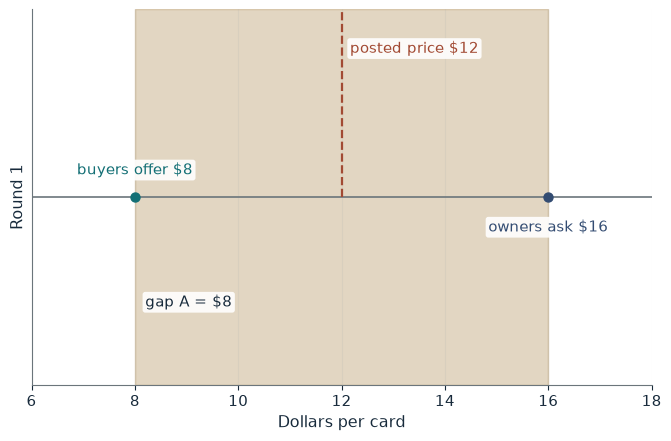

Owners' ask                             $16
Buyers' offer                           $8
Valuation gap A                         $8
Trade at posted price (typical quotes)  No

Worked steps:
  1. A = ask - offer = 16 - 8 = 8
  2. Owners sell if 12 >= 16: no
  3. Buyers buy if 12 <= 8: no
  4. Midpoint of offer and ask = (8 + 16) / 2 = 12

Novices (round 1): A = 16 - 8 = 8 dollars. At $12 no trade happens: owners want at least $16 and buyers pay at most $8. With these typical quotes no single price satisfies both sides; trades near the $12 midpoint need traders whose own quotes are closer than average. Experience shrinks the gap from $8 to $2, a fall of $6, but the average alone cannot separate learning from selection.


In [2]:
show(gap_picture(r=1, p=12))

Change one input, `p`, and hold the others at the book's values:

In [3]:
sweep(gap_picture, 'p', [9, 11, 12], {'r': 11}, ['Valuation gap A', 'Trade at posted price (typical quotes)'])

p | Valuation gap A | Trade at posted price (typical quotes)
9 | $2 | No
11 | $2 | No
12 | $2 | No


At a \$12 posted price novices do not trade, since owners want \$16. Experience cuts the gap by \$6 to \$2, and trades can occur near the \$11 midpoint among traders whose own quotes are closer than average. The average alone cannot tell learning from selection.

## 2. Beauty-contest convergence: guess two thirds of the average

Six analysts choose from 0 to 100 and the prize goes to the choice closest to $p=2/3$ of the mean. A level-k thinker picks $50p^k$.

$$\bar{x}_1=\frac{50+40+35+30+25+18}{6}=33,$$

$$\bar{x}_2=\frac{99}{6}=16.5, \qquad t_2=\frac{2}{3}(16.5)=11.$$

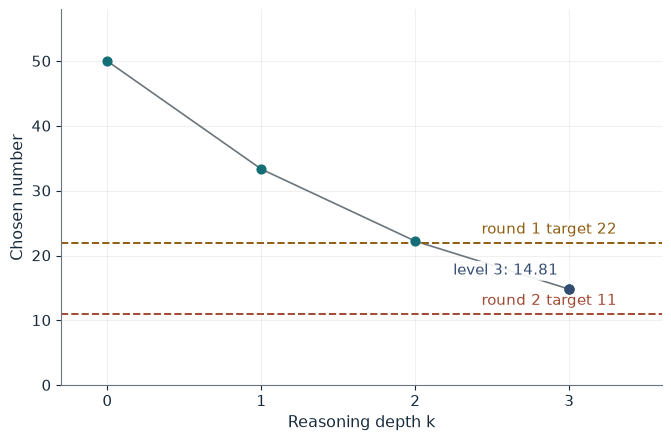

Level-k choice  14.81
Round 1 mean    33
Round 1 target  22
Round 1 winner  25
Round 2 mean    16.5
Round 2 target  11

Worked steps:
  1. Level-0 choice = 50
  2. Level 3 choice = 50 x (2/3)^3 = 14.81
  3. Round 1 mean = (50 + 40 + 35 + 30 + 25 + 18) / 6 = 198 / 6 = 33
  4. Round 1 target = (2/3) x 33 = 22, so 25 (3 away) wins
  5. Round 2 mean = 99 / 6 = 16.5, target = (2/3) x 16.5 = 11

A level-3 thinker best responds to level 2: 50 x (2/3)^3 = 14.81. With p = 2/3 the mean falls from 33 to 16.5 between rounds: choices move toward the zero equilibrium without reaching it.


In [4]:
show(level_picture(p='2/3', k=3))

Change one input, `k`, and hold the others at the book's values:

In [5]:
sweep(level_picture, 'k', [0, 1, 2, 3], {'p': '2/3'}, ['Level-k choice'])

k | Level-k choice
0 | 50.00
1 | 33.33
2 | 22.22
3 | 14.81


The level sequence is 50, 33.33, 22.22, 14.81. In round one the target is 22 and 25 wins; in round two the mean falls to 16.5 and the target to 11. With $p=1$ (`p='1'`) any common choice is stable and zero is no longer selected.

## 3. Double-auction convergence: continuous trading versus a sealed round

Buyer values are 100, 90, 80, 70 and seller costs 30, 50, 75, 95. Pairing them gives gains 70, 40, 5 and -25, so three trades are efficient:

$$\$70+\$40+\$5=\$115,$$

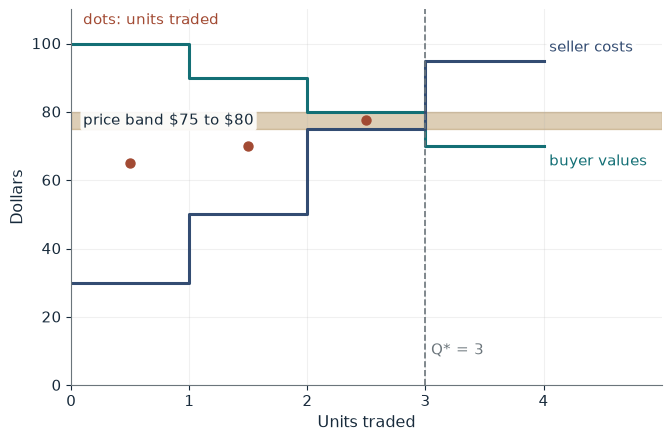

Efficient quantity Q*       3
Maximum surplus             $115
Trades in this institution  3
Realized surplus            $115
Competitive price band      $75 to $80

Worked steps:
  1. Gains by pair: 100 - 30 = 70, 90 - 50 = 40, 80 - 75 = 5, 70 - 95 = -25
  2. Q* = 3 pairs with positive gains; maximum surplus = 70 + 40 + 5 = 115
  3. Price band: from 75 to 80
  4. The double auction trades all 3 efficient units: surplus 115

Pairing the highest values with the lowest costs gives gains 70, 40, 5, -25, so Q* = 3 and maximum surplus is 70 + 40 + 5 = 115 dollars. Repeated bids and asks reach all 3 efficient trades, so the realized surplus is the full $115, however prices split it.


In [6]:
show(auction_picture(inst='continuous', c3=75))

Change one input, `c3`, and hold the others at the book's values:

In [7]:
sweep(auction_picture, 'c3', [60, 75, 85], {'inst': 'sealed'}, ['Efficient quantity Q*', 'Maximum surplus', 'Realized surplus'])

c3 | Efficient quantity Q* | Maximum surplus | Realized surplus
60 | 3 | $130 | $70
75 | 3 | $115 | $70
85 | 2 | $110 | $70


The double auction realizes all \$115. In the sealed round only the \$65 bid crosses the \$40 ask, so one unit trades and \$70 is realized, whatever the third seller's cost.

## 4. Preference reversal: choice and price disagree

Lottery P pays \$30 with probability 0.80; lottery D pays \$100 with probability 0.25. Elena chooses P but states selling prices \$20 for P and \$28 for D.

$$\operatorname{EV}(P)=0.80(\$30)=\$24,$$

$$\operatorname{EV}(D)=0.25(\$100)=\$25.$$

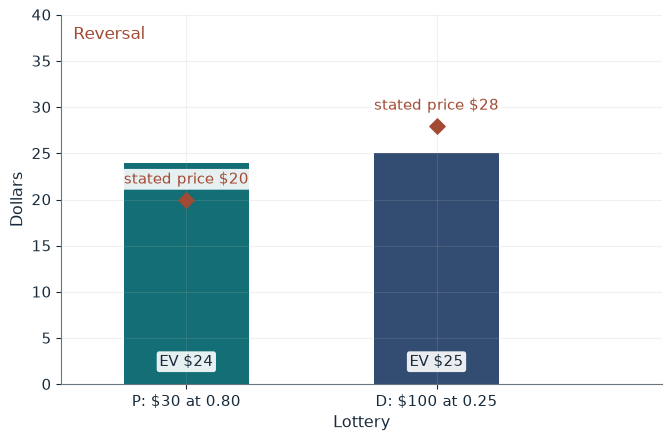

EV(P)                $24
EV(D)                $25
Direct choice        P
Pricing ranks first  D
Reversal             Yes

Worked steps:
  1. EV(P) = 0.80 x 30 = 24
  2. EV(D) = 0.25 x 100 = 25
  3. Stated prices: CE(P) = 20, CE(D) = 28, so pricing ranks D first
  4. Direct choice ranks P first: reversal

EV(P) = 0.80 x 30 = 24 and EV(D) = 0.25 x 100 = 25 dollars, so expected value favours D. Elena chooses P directly, but prices P at $20 and D at $28, so pricing ranks D first. Choice and pricing disagree: a preference reversal.


In [8]:
show(reversal_picture(q_d=0.25, ce_d=28))

Change one input, `ce_d`, and hold the others at the book's values:

In [9]:
sweep(reversal_picture, 'ce_d', [18, 28], {'q_d': 0.25}, ['Pricing ranks first', 'Reversal'])

ce_d | Pricing ranks first | Reversal
18 | P | No
28 | D | Yes


Pricing ranks D first while choice ranks P first: the two procedures cross. If D's stated price were \$18, pricing would rank P first and agree with choice.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

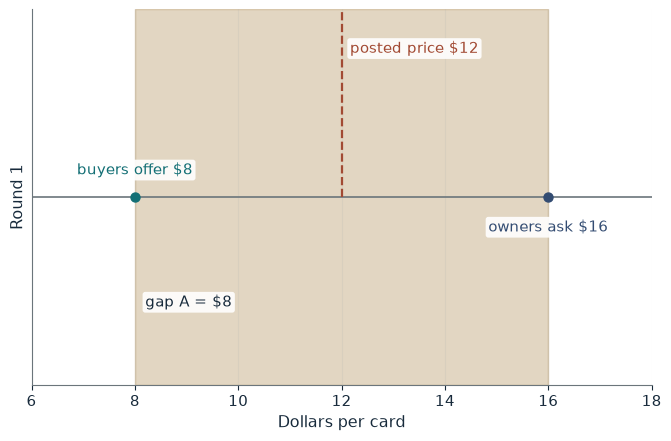

Owners' ask                             $16
Buyers' offer                           $8
Valuation gap A                         $8
Trade at posted price (typical quotes)  No

Worked steps:
  1. A = ask - offer = 16 - 8 = 8
  2. Owners sell if 12 >= 16: no
  3. Buyers buy if 12 <= 8: no
  4. Midpoint of offer and ask = (8 + 16) / 2 = 12

Novices (round 1): A = 16 - 8 = 8 dollars. At $12 no trade happens: owners want at least $16 and buyers pay at most $8. With these typical quotes no single price satisfies both sides; trades near the $12 midpoint need traders whose own quotes are closer than average. Experience shrinks the gap from $8 to $2, a fall of $6, but the average alone cannot separate learning from selection.


In [10]:
show(gap_picture(r=1, p=12))

## Practice

**1.** After ten rounds, what midpoint price splits the remaining gap?

<details><summary>Answer</summary>

(12 + 10) / 2 = \$11.

</details>

**2.** With p = 1/2, what does a level-2 thinker choose?

<details><summary>Answer</summary>

50 x (1/2)^2 = 12.5.

</details>

**3.** If the third seller's cost were \$85, how many efficient trades and what surplus?

<details><summary>Answer</summary>

80 - 85 < 0, so Q* = 2 and the surplus is 70 + 40 = \$110.

</details>